# ToMATo vs DBSCAN

Compares the ToMATo NEMI run with the DBSCAN NEMI run (min_samples 100) on the same 50-date fronts and the same
10 UMAP members. This section loads the inputs: the raw front table with its geography, the member embeddings both
runs clustered, and the two NEMI outputs.

In [16]:
import json
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.colors import LogNorm, Normalize
from scipy.stats import skew

import fronts_dataloader.fronts_dataset as fd
from fronts_dataloader.fronts_dataset import FrontDataSource, RawFronts
from nemi.cluster_colocation import _bin_index, contingency_table_per_ensemble, greedy_selection
from visualization.visualization import _PROJ, _global_ax

STORE = "s3://dbof/globals_for_cutouts/v2_2_03/Fronts/V5/SURF/fronts.zarr"
S3_ENDPOINT = "https://s3-west.nrp-nautilus.io"
EMBEDDING_FILE = "umap50_nn_30_v3.npz"
RUNS = {"tomato": "nemi_out_tomato_k100g30_tau0.625_v3.npz",
        "dbscan": "/Users/jaketallman/Desktop/NEMI_runs/1021/nemi_out_min_samples_100_v3.npz"}
# the ToMATo run's export: its dates are the runs' dates, and its (date, label) order checks the rebuilt rows
EXPORT_FILE = "nemi_out_tomato_k100g30_tau0.625_v3_fronts.parquet"
# per-front distance to land and water body; holds the 50 dates despite its name
LAND_CACHE = "fronts_land_25dates.parquet"

## Fronts

Rebuilt the way `NEMI_front_finding.ipynb` builds them: load, derived rotation columns, the ice, size, land and
weak-front filters, then the same `select`. `ds.row_index` gives the rows NEMI clustered, in its order, and the store
adds each front's bounding box and lat/lon extents.

In [6]:
FEATURES_RAW = ["npix", "length_km", "num_branches", "mean_curvature", "orientation",
                "Theta", "Salt", "Eta",
                "oceTAUX", "oceTAUY", "wind_stress_curl", "ekman_pumping", "v_ekman", "u_ekman", "oceQnet",
                "rossby_number", "relative_vorticity", "turner_angle", "strain_n", "strain_s", "strain_mag", "divergence",
                "coriolis_f", "okubo_weiss",
                "gradtheta2", "gradsalt2", "gradb2", "gradeta2",
                "density", "buoyancy",
                "SIarea_max"]
dates = json.loads(pq.ParquetFile(EXPORT_FILE).schema_arrow.metadata[b"acf_fronts"])["dates"]

source = FrontDataSource(STORE, storage_options={"endpoint_url": S3_ENDPOINT})
raw = RawFronts.load(source, dates=dates, features=FEATURES_RAW)
print(f"{len(raw):,} fronts on {len(dates)} dates")

5,669,718 fronts on 50 dates


In [7]:
# rotation fields made hemisphere-consistent (x * sign f; NaN where the band crosses the equator),
# and the Rossby number with |f| floored at its EQUATOR_DEG value
t = raw.table
sign_f = np.select([t["coriolis_f_min"] > 0, t["coriolis_f_max"] < 0], [1.0, -1.0], default=np.nan)
for src, new in (("relative_vorticity", "cyclonic_vorticity"), ("wind_stress_curl", "cyclonic_wind_curl")):
    t[f"{new}_mean"] = t[f"{src}_mean"] * sign_f
    t[f"{new}_std"] = t[f"{src}_std"]
    t[f"{new}_skew"] = t[f"{src}_skew"] * sign_f
    if new not in fd.IHS_PREFIX:
        fd.IHS_PREFIX.append(new)
EQUATOR_DEG = 5.0
abs_f = np.maximum(t["coriolis_f_mean"].abs(), 2 * 7.2921e-5 * np.sin(np.deg2rad(EQUATOR_DEG)))
t["rossby_floored_mean"] = t["cyclonic_vorticity_mean"] / abs_f
t["rossby_floored_std"] = t["cyclonic_vorticity_std"] / abs_f

In [8]:
def kept(raw, mask, what):
    print(f"{what}: dropped {(~mask).sum():,} ({100 * (~mask).mean():.1f}%), {mask.sum():,} remain")
    return RawFronts(raw.table[mask].reset_index(drop=True), raw.groups, raw.source_info)


raw = kept(raw, ~(raw.table["SIarea_max"].to_numpy(float) > 0.0), "touching ice")
raw = kept(raw, raw.table["npix"].to_numpy(float) > 15, "15 pixels or fewer")

land = pd.read_parquet(LAND_CACHE)
if set(land["date"].astype(str)) != set(dates):
    raise ValueError(f"{LAND_CACHE} does not cover these dates; rebuild it with the land cell in NEMI_front_finding")
raw = RawFronts(raw.table.merge(land, on=["date", "label"], how="left", validate="one_to_one"),
                raw.groups, raw.source_info)
if raw.table["body"].isna().any():
    raise ValueError(f"{int(raw.table['body'].isna().sum()):,} fronts missing from {LAND_CACHE}")
raw = kept(raw, ((raw.table["min_px_to_land"] > 4) & raw.table["open_ocean"].astype(bool)).to_numpy(),
           "within 4 px of land or in enclosed water")

t = raw.table
weak_b = (t["gradb2_mean"] < np.nanpercentile(t["gradb2_mean"], 25)).to_numpy()
strong_ts = ((t["gradtheta2_mean"] >= np.nanpercentile(t["gradtheta2_mean"], 50))
             | (t["gradsalt2_mean"] >= np.nanpercentile(t["gradsalt2_mean"], 50))).to_numpy()
raw = kept(raw, ~(weak_b & ~strong_ts), "weak in buoyancy and in both T and S")

touching ice: dropped 925,615 (16.3%), 4,744,103 remain
15 pixels or fewer: dropped 1,842,954 (38.8%), 2,901,149 remain
within 4 px of land or in enclosed water: dropped 134,800 (4.6%), 2,766,349 remain
weak in buoyancy and in both T and S: dropped 460,445 (16.6%), 2,305,904 remain


In [9]:
FEATURES = ["front_wind_angle", "cyclonic_wind_curl", "oceQnet", "rossby_floored_mean", "rossby_floored_std",
            "strain_mag", "divergence", "okubo_weiss", "gradtheta2", "gradsalt2", "gradb2", "gradeta2"]
ds = raw.select(FEATURES, stats=("mean", "std"), scaling="standardize", nan_policy="drop_rows", div_by_f=False,
                ihs_channels=True, log_channels=True, fill_value=0, missing_indicator=True)

fronts = raw.table.iloc[ds.row_index].reset_index(drop=True)
BBOX = ["y0", "y1", "x0", "x1", "lat_min", "lat_max", "lon_min", "lon_max"]
missing = [c for c in BBOX if c not in fronts.columns]
if missing:
    with ThreadPoolExecutor(max_workers=8) as pool:
        geo = pd.concat(pool.map(lambda dt: source.store.geometry(dt, columns=["label", *missing]).assign(date=dt),
                                 dates), ignore_index=True)
    fronts = fronts.merge(geo, on=["date", "label"], how="left", validate="one_to_one")
    if fronts[missing].isna().any().any():
        raise ValueError(f"{int(fronts[missing].isna().any(axis=1).sum()):,} fronts missing from the store geometry")

export_rows = pq.read_table(EXPORT_FILE, columns=["date", "label"]).to_pandas()
if not (len(fronts) == len(export_rows)
        and np.array_equal(fronts["date"].astype(str).to_numpy(), export_rows["date"].astype(str).to_numpy())
        and np.array_equal(fronts["label"].to_numpy(np.int64), export_rows["label"].to_numpy(np.int64))):
    raise ValueError(f"the rebuilt fronts are not the rows of {EXPORT_FILE}")
n_fronts = len(fronts)
print(f"{n_fronts:,} fronts clustered, {fronts.shape[1]} columns; rows match {EXPORT_FILE}")

2,303,529 fronts clustered, 233 columns; rows match nemi_out_tomato_k100g30_tau0.625_v3_fronts.parquet


## Embedding

The 10 UMAP members both runs clustered.

In [10]:
embedding_file = np.load(EMBEDDING_FILE)
embeddings = embedding_file["embeddings"]          # (members, fronts, dims)
n_members = embeddings.shape[0]
if embeddings.shape[1] != n_fronts:
    raise ValueError(f"{EMBEDDING_FILE} has {embeddings.shape[1]:,} fronts, the front table {n_fronts:,}")
print(f"{n_members} members, {n_fronts:,} fronts, {embeddings.shape[2]} dimensions")
print(embedding_file["params"])

10 members, 2,303,529 fronts, 3 dimensions
{"device": "gpu", "embedding_dict": {"n_components": 3, "n_neighbors": 30, "min_dist": 0.0}, "clustering_dict": {"method": "agglomerative", "linkage": "ward", "n_clusters": 30, "n_neighbors": 40}}


## NEMI runs

Each file holds what NEMI saves: member labels (NaN = noise), consensus clusters (-1 = noise), entropy and the share
of members casting no vote. Both runs must have clustered these embeddings.

In [11]:
runs = {}
for name, path in RUNS.items():
    d = np.load(path)
    if not np.array_equal(d["embeddings"], embeddings):
        raise ValueError(f"{path} was not clustered on {EMBEDDING_FILE}")
    runs[name] = {k: d[k] for k in ("clusters", "entropy", "unassigned_frac", "member_clusters")}

summary = {}
for name, r in runs.items():
    c, m = r["clusters"], r["member_clusters"]
    sizes = np.bincount(c[c >= 0])
    counts = [np.unique(x[~np.isnan(x)]).size for x in m]
    summary[name] = {"consensus clusters": int((sizes > 0).sum()), "of 100+ fronts": int((sizes >= 100).sum()),
                     "consensus noise %": 100 * np.mean(c < 0), "member noise %": 100 * np.isnan(m).mean(),
                     "member clusters": f"{int(np.median(counts))} ({min(counts)}-{max(counts)})",
                     "entropy median": np.median(r["entropy"]), "entropy mean": r["entropy"].mean()}
pd.DataFrame(summary).T.round(3)

,consensus clusters,of 100+ fronts,consensus noise %,member noise %,member clusters,entropy median,entropy mean
tomato,26,26,0.000043,0.0,25 (21-28),0.0,0.1362
dbscan,115,49,80.503046,79.606604,181 (168-196),0.0,0.030933


## Cluster pairs

NEMI's matching step between the two runs' consensus clusters: base clusters, largest first, each take the
unused cluster of the other run they overlap most (IoU), if any. Pairs are consensus cluster ids.

In [14]:
def as_member(clusters):
    """Consensus labels (-1 noise) in NEMI's member form, relabeled by size (largest 0, NaN noise), and
    the consensus id of each new label."""
    ids, counts = np.unique(clusters[clusters >= 0], return_counts=True)
    ids = ids[np.argsort(-counts, kind="stable")]
    lut = np.zeros(clusters.max() + 1)
    lut[ids] = np.arange(ids.size)
    return np.where(clusters >= 0, lut[np.maximum(clusters, 0)], np.nan), ids


def nemi_pairs(base, compare):
    """(base ids, compare ids) matched by assess_overlap_fast's matching step, in base size order.  Each side
    keeps its own cluster count: assess_overlap_fast counts compare labels at or above the base's count as noise."""
    b, b_ids = as_member(base)
    c, c_ids = as_member(compare)
    kb, kc = b_ids.size, c_ids.size
    iou = contingency_table_per_ensemble(_bin_index(b, kb) * (kc + 1), _bin_index(c, kc), kb, kc)
    match = greedy_selection(iou, kb, kc)[:kc]
    matched = np.flatnonzero(match >= 0)
    matched = matched[np.argsort(match[matched])]
    return b_ids[match[matched]], c_ids[matched]


pairs = {}
for base, compare in (("tomato", "dbscan"), ("dbscan", "tomato")):
    b, c = nemi_pairs(runs[base]["clusters"], runs[compare]["clusters"])
    pairs[base] = pd.DataFrame({base: b, compare: c})
    print(f"{base} as base: {len(b)} pairs")
    display(pairs[base])

tomato as base: 9 pairs


,tomato,dbscan
0,0,1
1,3,0
2,1,12
3,2,16
4,4,2
5,6,4
6,5,3
7,7,5
8,20,72


dbscan as base: 9 pairs


,dbscan,tomato
0,0,1
1,1,0
2,2,4
3,3,5
4,4,6
5,5,7
6,6,3
7,16,2
8,72,20


## Pair maps and distributions

One row per cluster pair, base first: where each cluster's fronts are, each cluster's entropy in its own run,
where the pair overlaps, each cluster in the embedding (as `plot_clusters_separately` draws it), and feature
distributions against every front's, drawn as in the viewer's profile.

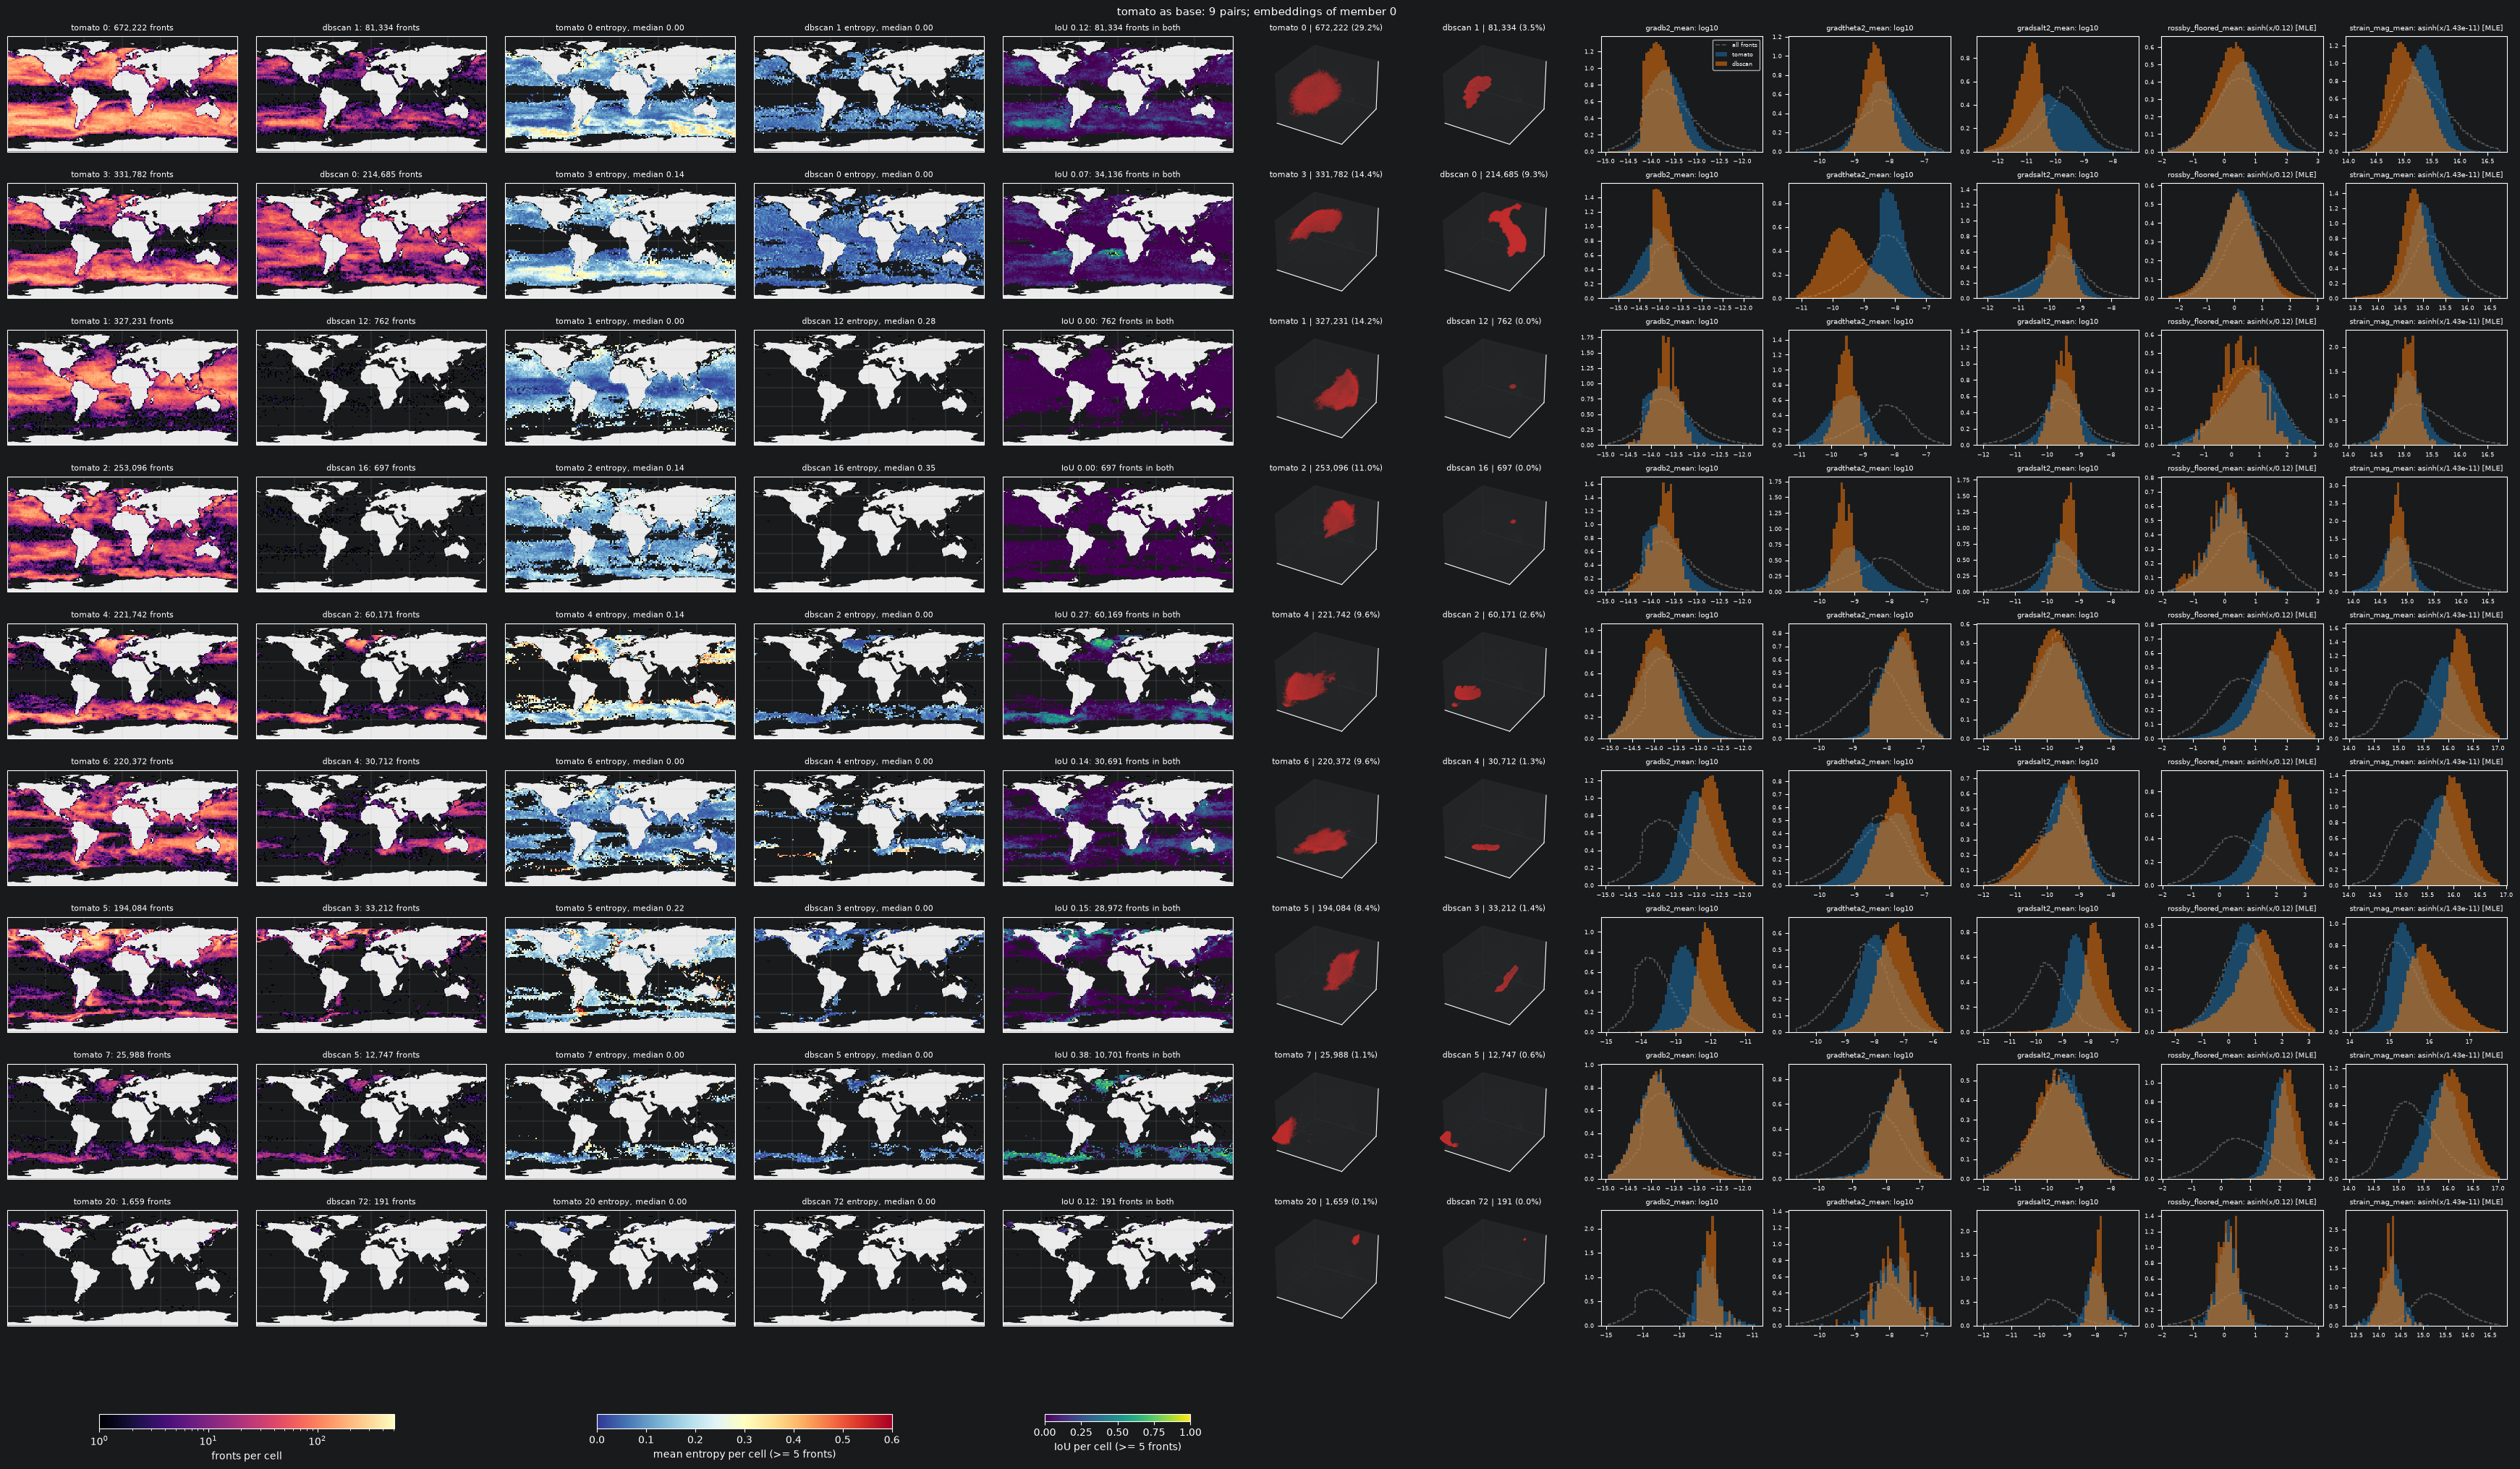

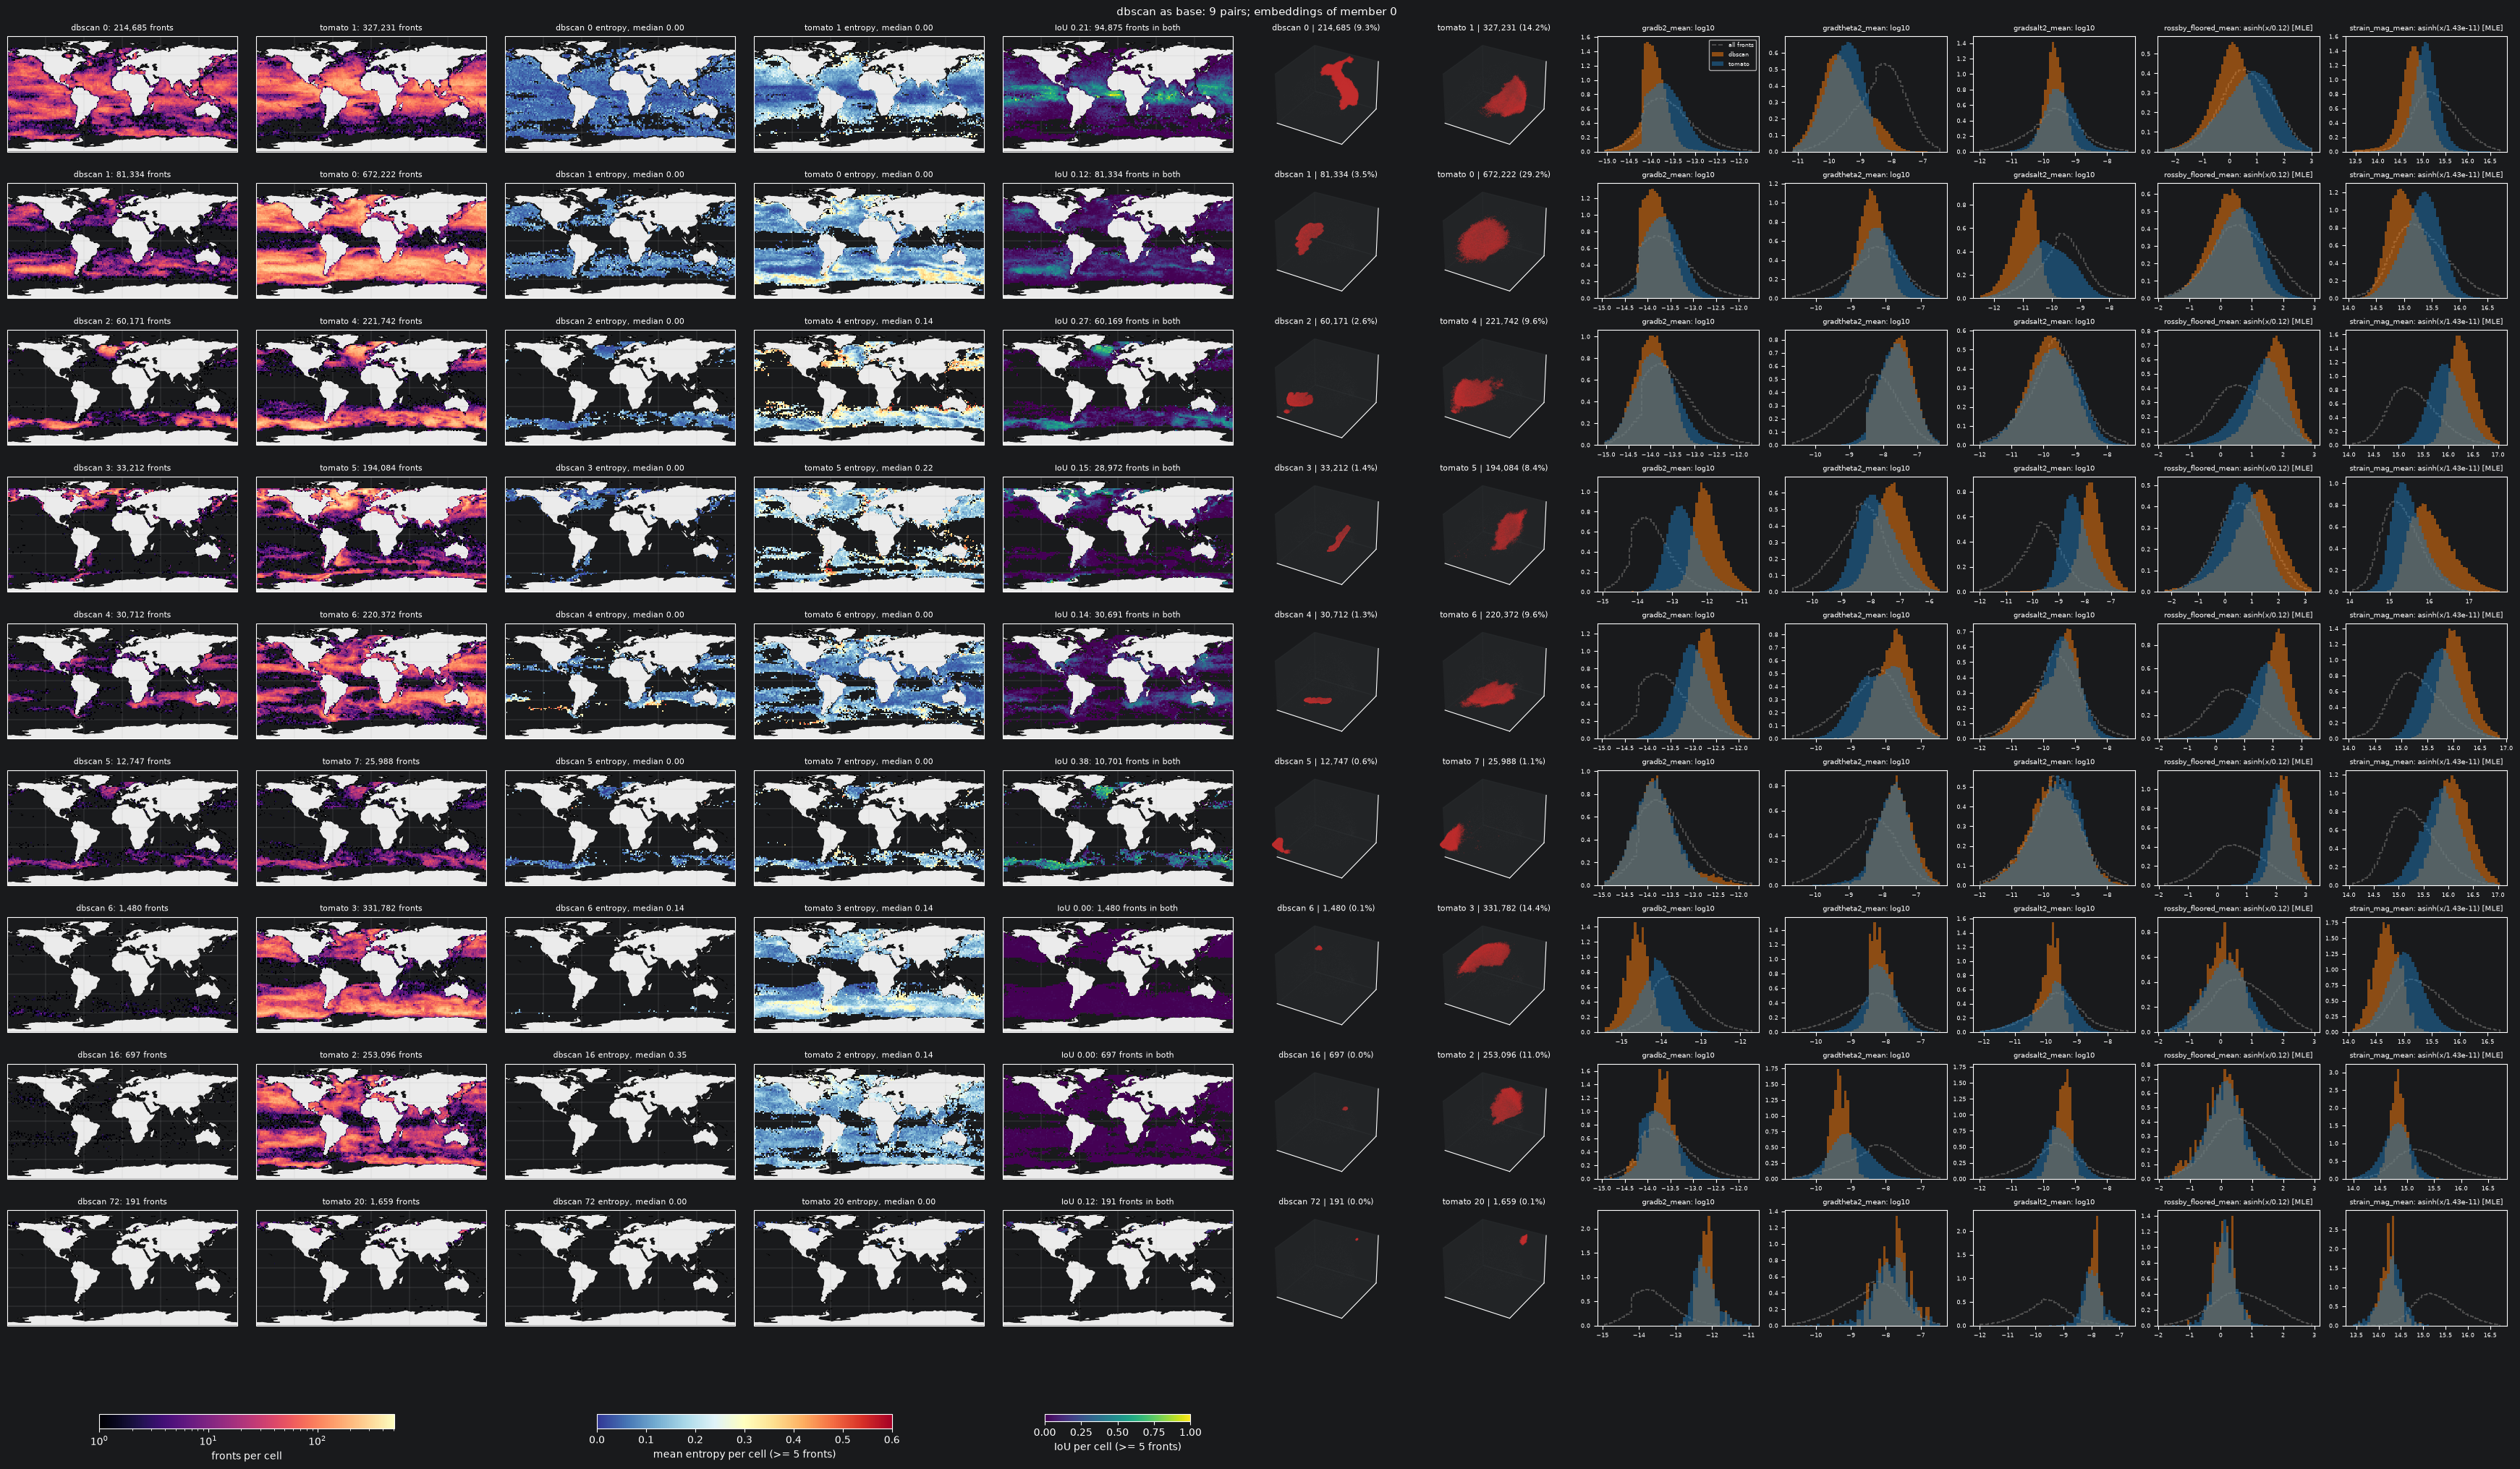

In [18]:
DEG = 2.0                # map cell size, degrees
MIN_CELL = 5             # entropy and overlap cells with fewer of the pair's fronts are left blank
ENTROPY_MAX = 0.6        # top of the entropy color scale; higher cells take the top color
STAT_COLUMNS = ["gradb2_mean", "gradtheta2_mean", "gradsalt2_mean", "rossby_floored_mean", "strain_mag_mean"]
RUN_COLORS = {"tomato": "tab:blue", "dbscan": "tab:orange"}
EMBEDDING_MEMBER = 0     # member whose embedding the embedding panels show
EMB_BG, EMB_FG = 80_000, 40_000    # every-front sample (gray) and most cluster fronts drawn per embedding panel

# centroid_lon is the mean of a front's pixel longitudes, so a front crossing +/-180 is placed on it
lon = fronts["centroid_lon"].to_numpy(float).copy()
lon[(fronts["lon_max"] - fronts["lon_min"]).to_numpy() > 180] = 180.0
lat = fronts["centroid_lat"].to_numpy(float)
lon_edges, lat_edges = np.arange(-180, 180 + DEG, DEG), np.arange(-90, 90 + DEG, DEG)
nx, ny = lon_edges.size - 1, lat_edges.size - 1
cell = (np.clip(((lat + 90) // DEG).astype(int), 0, ny - 1) * nx
        + np.clip(((lon + 180) // DEG).astype(int), 0, nx - 1))

emb = embeddings[EMBEDDING_MEMBER]
rng = np.random.default_rng(0)
emb_bg = rng.choice(len(emb), min(EMB_BG, len(emb)), replace=False)
emb_lim = [np.percentile(emb[:, d], (0.5, 99.5)) for d in range(emb.shape[1])]


def cell_sum(mask, weights=None):
    """Sum of weights (a count without them) over the fronts in mask, per map cell, as a (lat, lon) grid."""
    return np.bincount(cell[mask], weights=None if weights is None else weights[mask],
                       minlength=nx * ny).reshape(ny, nx)


def stat_values(col):
    """(values, label, span) as the viewer's profile shows a column: a clustered feature after its transform,
    any other column in its own units, log10 when that makes it more symmetric.  span is every front's
    0.5-99.5 percentile range."""
    if col in ds.feature_names:
        values, label = ds.raw[:, ds.feature_names.index(col)], f"{col}: {ds.transform_label(col)}"
    else:
        values, label = fronts[col].to_numpy(float), col
        ok = values[np.isfinite(values)]
        sample = ok[::max(1, ok.size // 200_000)]
        if ok.size and ok.min() > 0 and abs(skew(np.log10(sample))) < abs(skew(sample)):
            values, label = np.log10(values), f"log10({col})"
    return values, label, np.nanpercentile(values, (0.5, 99.5))


def stat_panel(ax, values, label, span, masks):
    """Density histograms of each cluster (filled) and of every front (gray dashed) on the same bins: every
    front's span widened to each cluster's own."""
    spans = [span, *(np.nanpercentile(values[m], (0.5, 99.5)) for m in masks.values())]
    edges = (min(s[0] for s in spans), max(s[1] for s in spans))
    ax.stairs(*np.histogram(values, bins=60, range=edges, density=True), color="0.33", ls="--", lw=1.2,
              label="all fronts")
    for name, m in masks.items():
        ax.stairs(*np.histogram(values[m], bins=60, range=edges, density=True), fill=True, alpha=0.5,
                  color=RUN_COLORS[name], label=name)
    ax.set_title(label, fontsize=7)
    ax.tick_params(labelsize=6)


def embedding_panel(ax, mask, title):
    """A cluster's fronts (red) against a sample of every front (gray), on the full embedding's limits, as in
    plot_clusters_separately."""
    idx = np.flatnonzero(mask)
    if idx.size > EMB_FG:
        idx = rng.choice(idx, EMB_FG, replace=False)
    ax.scatter(*emb[emb_bg].T, s=0.72, alpha=0.12, linewidths=0, color="0.55")
    ax.scatter(*emb[idx].T, s=1.2, alpha=0.55, linewidths=0, color="#c53030")
    ax.set(xlim=emb_lim[0], ylim=emb_lim[1], zlim=emb_lim[2], xticks=[], yticks=[], zticks=[])
    ax.set_title(title, fontsize=8)


def plot_pairs(table):
    """One row per cluster pair in table (a column per run, base first): each cluster's fronts per map cell,
    the mean entropy per cell of each cluster's fronts in its own run, the pair's IoU per cell, each cluster
    in member EMBEDDING_MEMBER's embedding, then STAT_COLUMNS for both clusters against every front."""
    names = list(table.columns)
    stats = [stat_values(c) for c in STAT_COLUMNS]
    masks = [{n: runs[n]["clusters"] == c for n, c in zip(names, row)} for row in table.itertuples(index=False)]
    counts = [{n: cell_sum(m) for n, m in row.items()} for row in masks]
    style = [dict(cmap="magma", norm=LogNorm(1, max(g.max() for row in counts for g in row.values()))),
             dict(cmap="RdYlBu_r", norm=Normalize(0, ENTROPY_MAX)),
             dict(cmap="viridis", norm=Normalize(0, 1))]
    widths = [3.6] * 5 + [2.4] * len(names) + [2.4] * len(stats)
    fig = plt.figure(figsize=(sum(widths), 2.1 * len(table) + 1.2), constrained_layout=True)
    gs = fig.add_gridspec(len(table), len(widths), width_ratios=widths)
    map_axes = [[], [], []]                  # location, entropy and overlap maps, for their colorbars
    for i, (row, mask, count) in enumerate(zip(table.itertuples(index=False), masks, counts)):
        both, either = mask[names[0]] & mask[names[1]], mask[names[0]] | mask[names[1]]
        grids = [(0, f"{n} {c}: {mask[n].sum():,} fronts", np.where(count[n] > 0, count[n], np.nan))
                 for n, c in zip(names, row)]
        grids += [(1, f"{n} {c} entropy, median {np.median(runs[n]['entropy'][mask[n]]):.2f}",
                   np.where(count[n] >= MIN_CELL, cell_sum(mask[n], runs[n]["entropy"]) / np.maximum(count[n], 1),
                            np.nan))
                  for n, c in zip(names, row)]
        k = cell_sum(either)
        grids.append((2, f"IoU {both.sum() / either.sum():.2f}: {both.sum():,} fronts in both",
                      np.where(k >= MIN_CELL, cell_sum(both) / np.maximum(k, 1), np.nan)))
        for j, (kind, title, grid) in enumerate(grids):
            ax = _global_ax(fig, (gs[i, j],))
            ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(grid), transform=_PROJ, zorder=2, **style[kind])
            ax.set_title(title, fontsize=8)
            map_axes[kind].append(ax)
        for j, (n, c) in enumerate(zip(names, row), start=len(grids)):
            embedding_panel(fig.add_subplot(gs[i, j], projection="3d"), mask[n],
                            f"{n} {c} | {mask[n].sum():,} ({100 * mask[n].mean():.1f}%)")
        first_stat = len(grids) + len(names)
        for j, (values, label, span) in enumerate(stats, start=first_stat):
            ax = fig.add_subplot(gs[i, j])
            stat_panel(ax, values, label, span, mask)
            if i == 0 and j == first_stat:
                ax.legend(fontsize=6)
    for axes, s, label in zip(map_axes, style, ("fronts per cell", f"mean entropy per cell (>= {MIN_CELL} fronts)",
                                                f"IoU per cell (>= {MIN_CELL} fronts)")):
        fig.colorbar(plt.cm.ScalarMappable(**s), ax=axes, location="bottom", shrink=0.6, label=label)
    return fig


for base, table in pairs.items():
    fig = plot_pairs(table)
    fig.suptitle(f"{base} as base: {len(table)} pairs; embeddings of member {EMBEDDING_MEMBER}", fontsize=11)
    plt.show()